# 06 · Challengers: LightGBM, CatBoost and an Explainable Boosting Machine

## What this notebook is, and where it sits in the project

Banks rarely trust one model. Next to the **champion** (the model in use) they keep **challengers**: different methods built on the same data, to answer "are we leaving performance on the table, and if so, why?" Notebook 05 built the first champion, a six-feature WoE logistic scorecard. This notebook builds three challengers:

* **LightGBM**, gradient-boosted trees, the standard high-performance method for tabular credit data, tuned with Optuna;
* **CatBoost**, a second boosting library with its own handling of categories (the winner of several published credit benchmarks);
* an **Explainable Boosting Machine (EBM)**, a *glass-box* model: every feature's effect is a curve you can plot, and every interaction a small two-way table.

It answers five questions:

1. How much better do flexible models rank borrowers than the scorecard?
2. **Where** does the gain come from: finer shapes within features, interactions between them, or extra features?
3. Would more data help (learning curve)?
4. How much is Bondora's own price worth (the D-012 sensitivity run)?
5. Are the challengers' PDs at the right level?

## Rules this notebook follows

* **Same samples, same target** as the champion (notebook 03), and the same leakage guard.
* **Tuning uses the train sample only**, with forward-chaining validation by issue year: fit on 2016 to 2017, check on 2018; fit on 2016 to 2018, check on 2019.
* **The test and out-of-time samples are used once**, for the final comparison, after every choice is made.
* **Monotone constraints only where economics and the train data agree** (D-029). The first version of this notebook also forced loan size, time since the last loan and the liabilities fields to one direction; the 2026-11-23 audit showed the data contradict those directions, and dropping them improved the model.

> **Correction (D-029).** The first version of step 6 concluded that "finer shapes add nothing; the gain is all interactions". That was wrong: the restricted models reused the number of trees tuned for the unrestricted model and were under-trained. Step 6 now tunes every model separately, and the conclusion changes.

Every step has **Why this step**, **the code**, **What the result shows**, **Recommended action**. The notebook reads the warehouse read-only and writes the challengers and their predictions to `data/processed/` (git-ignored). It takes about 15 to 25 minutes (most of it is the Optuna search).

## Key terms used in this notebook

| Term | Meaning |
|---|---|
| **Decision tree** | A model that splits loans into groups by yes/no questions ("tenure above 300 days?") and predicts each group's default rate. |
| **Gradient boosting (LightGBM, CatBoost)** | Hundreds of small trees, each correcting the errors of the ones before. Very flexible: can follow any shape and any interaction. Hard to read: a *black box*. |
| **Explainable Boosting Machine (EBM)** | Boosting restricted to one feature at a time (plus a few chosen pairs). The result is a sum of one curve per feature and a few two-way tables: a *glass box*, essentially a scorecard with very fine bins learned jointly. |
| **Glass box / black box** | A glass-box model can be read directly (each feature's effect is visible); a black box needs extra tools (SHAP) to be explained. |
| **Optuna** | A library that searches model settings efficiently (it learns which settings look promising and tries more of those). |
| **Early stopping** | Stop adding trees when the validation score stops improving, to avoid fitting noise. |
| **Monotone constraint** | Forces the prediction to only rise (or only fall) as a feature grows, for example "more tenure never means more risk". |
| **Interaction** | When the effect of one feature depends on another, for example recent borrowing matters more in Finland than in Estonia. |
| **Additive model** | A model with no interactions: the score is a sum of one effect per feature. Scorecards and EBMs without pairs are additive. |
| **Forward-chaining validation** | Train on earlier years, validate on the next year. |
| **Fitting graph** | Train and validation score as model complexity grows. When validation stops rising while train keeps rising, the model has started to memorise noise. |
| **Learning curve** | Test score as the amount of training data grows. |
| **Champion / challenger** | The model in use, and the alternatives it is regularly compared with. |

## Step 0. Setup

### Why this step
Load the libraries and the pipeline functions. `cvxpy` is imported first: on Windows it must load before pandas (D-026). The v1 champion comes from `data/processed/scorecard.json` and `binning_process.pkl` (notebook 05 or `make train`).

In [1]:
import logging
logging.disable(logging.WARNING)              # hide solver-probe messages from cvxpy
import cvxpy  # noqa: F401  load before pandas on Windows (D-026)
import json
import pickle
import sys
import warnings
from pathlib import Path

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import statsmodels.api as sm
from catboost import CatBoostClassifier
from interpret.glassbox import ExplainableBoostingClassifier
from optbinning import BinningProcess, OptimalBinning

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "pdengine").exists())
PROC = ROOT / "data" / "processed"
for f in ["model_samples.parquet", "binning_process.pkl", "scorecard.json"]:
    assert (PROC / f).exists(), f"{f} missing: run make train (or notebooks 03 to 05)"
try:
    from pdengine import settings as S
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    from pdengine import settings as S
from pdengine.dataset import load_model_data
from pdengine.registry import check_model_columns, load_registry
from pdengine.scorecard import Scorecard, brier, gini, ks
from pdengine.selection import fit_bins, screen_features, transform

con = duckdb.connect(str(S.DB_PATH), read_only=True)
reg = load_registry()
SEED = S.SEED

BLUE, GREY, ORANGE, GREEN, PURPLE = "#2a78d6", "#b5b3ad", "#d97a2b", "#3c9a5f", "#7b5ea7"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print("LightGBM", lgb.__version__, "| Optuna", optuna.__version__)

LightGBM 4.5.0 | Optuna 5.1.0


### What the result shows
Libraries loaded.

### Recommended action
None.

## Step 1. Data, the v1 champion, and the challengers' inputs

### Why this step
The challengers must see the same loans and the same allowed features as the champion. `load_model_data` builds the 24 candidate, derived and history features through the registry, exactly as `make train` does, and the v1 champion's PDs are recomputed from its saved bins and coefficients.

The boosting models take the **raw** feature values, not WoE: they find their own cut points and handle empty values themselves.

**Monotone constraints (D-029).** A constraint is kept only if economics fixes the direction *and* the train data agree. The table below shows the train default rate by quintile for the features whose constraint was dropped: none of them moves in one direction.

In [2]:
samples = pd.read_parquet(PROC / "model_samples.parquet")
data = load_model_data(con, samples, reg)
y, sample, country = data.y, data.sample, data.country
is_train, is_test, is_oot = sample.eq("train"), sample.eq("test"), sample.eq("oot")
year = data.issue_date.dt.year

bins_v1 = BinningProcess.load(str(PROC / "binning_process.pkl"))
champion = Scorecard.from_json(PROC / "scorecard.json")
woe = transform(bins_v1, data.X, "woe")
pd_champion = champion.predict_pd(woe)
SIX = champion.features

X = data.X.copy()                                # LightGBM: categories as pandas categories
for c in X.columns:
    if X[c].dtype == object:
        X[c] = pd.Categorical(X[c], categories=sorted(X.loc[is_train, c].dropna().unique()))
XS = data.X.copy()                               # CatBoost and EBM: categories as text
for c in XS.columns:
    if XS[c].dtype == object:
        XS[c] = XS[c].fillna("missing").astype(str)
ALL = list(X.columns)
check_model_columns(ALL, reg)                    # the leakage guard, on the challengers' inputs too
MONOTONE = S.MONOTONE
print(f"{len(X):,} loans; v1 champion features: {SIX}")
print(f"Candidates: {len(ALL)}; monotone constraints: {MONOTONE}")

dropped = ["AppliedAmount", "days_since_last_loan", "ExistingLiabilities", "LiabilitiesTotal"]
rates = {}
for f in dropped:
    q = pd.qcut(data.X.loc[is_train, f].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
    rates[f] = y[is_train].groupby(q).mean()
(pd.DataFrame(rates).T * 100).round(1).rename_axis("train default rate % by quintile (Q1 = lowest value)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

155,725 loans; v1 champion features: ['country_bureau_grade', 'days_since_first_loan', 'days_since_last_loan', 'HomeOwnershipType', 'AppliedAmount', 'income_vs_country_median']
Candidates: 24; monotone constraints: {'days_since_first_loan': -1, 'NoOfPreviousLoansBeforeLoan': -1, 'AmountOfPreviousLoansBeforeLoan': -1, 'NewCreditCustomer': 1, 'income_vs_country_median': -1}


,Q1,Q2,Q3,Q4,Q5
train default rate % by quintile (Q1 = lowest value),,,,,
AppliedAmount,29.8,20.8,40.6,31.7,34.0
days_since_last_loan,29.9,26.7,23.9,22.3,15.8
ExistingLiabilities,39.8,35.9,30.2,26.0,25.0
LiabilitiesTotal,39.2,28.6,28.4,28.0,32.6


### What the result shows
155,725 loans, the six v1 features and 24 candidates, all through the leakage guard. In the quintile table, loan size and liabilities go up and down rather than in one direction, and the time since the last loan falls and then rises again. Earlier versions forced these features to be monotone, which pushed the model against the data.

### Recommended action
Keep only the five constraints in `settings.MONOTONE` (customer tenure, the number and amount of previous loans, the new-customer flag, income relative to the country median).

## Step 2. Tune LightGBM on the train sample only

### Why this step
LightGBM has settings (tree size, leaf size, learning rate, sampling, regularisation) that change its result. Optuna searches them, scoring each candidate by the **forward-chaining Gini** (mean of the 2018 and 2019 folds). The number of trees is set by early stopping inside each fold. The test and out-of-time samples play no part.

The search runs for the six v1 features and for all 24 candidates. A **fitting graph** then varies the tree size around the best setting.

In [3]:
FOLDS = [(is_train & (year < v), is_train & (year == v)) for v in [2018, 2019]]


def lgbm(cols, **params):
    return lgb.LGBMClassifier(monotone_constraints=[MONOTONE.get(c, 0) for c in cols],
                              monotone_constraints_method="advanced", subsample_freq=1,
                              random_state=SEED, verbose=-1, **params)


def lgbm_cv(cols, params, train_gini=False):
    """Forward-chaining validation Gini, best tree count (and train Gini)."""
    out = []
    for fit_on, check_on in FOLDS:
        m = lgbm(cols, n_estimators=3000, **params).fit(
            X.loc[fit_on, cols], y[fit_on], eval_set=[(X.loc[check_on, cols], y[check_on])],
            eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
        out.append((gini(y[check_on], m.predict_proba(X.loc[check_on, cols])[:, 1]),
                    gini(y[fit_on], m.predict_proba(X.loc[fit_on, cols])[:, 1]), m.best_iteration_))
    va, tr_, it = np.mean(out, axis=0)
    return (va, int(round(it)), tr_) if train_gini else (va, int(round(it)))


def search(cols, n_trials=30):
    def objective(trial):
        params = dict(
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            num_leaves=trial.suggest_int("num_leaves", 4, 64, log=True),
            min_child_samples=trial.suggest_int("min_child_samples", 50, 2000, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
            min_split_gain=trial.suggest_float("min_split_gain", 0.0, 1.0),
            cat_smooth=trial.suggest_float("cat_smooth", 1, 100, log=True))
        return lgbm_cv(cols, params)[0]
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    valid, trees = lgbm_cv(cols, study.best_params)
    return {"params": study.best_params, "trees": trees, "valid_gini": valid}


TUNED = {"6 v1 features": search(SIX), "24 candidates": search(ALL)}
pd.DataFrame({k: {"validation Gini": v["valid_gini"], "trees": v["trees"], **v["params"]}
              for k, v in TUNED.items()}).round(4)

,6 v1 features,24 candidates
validation Gini,0.4558,0.4651
trees,81.0000,100.0000
learning_rate,0.0399,0.0377
num_leaves,28.0000,27.0000
min_child_samples,53.0000,83.0000
subsample,0.9850,0.8529
colsample_bytree,0.8995,0.5932
reg_lambda,0.0089,8.7635
min_split_gain,0.1818,0.2981
cat_smooth,2.3271,8.1475


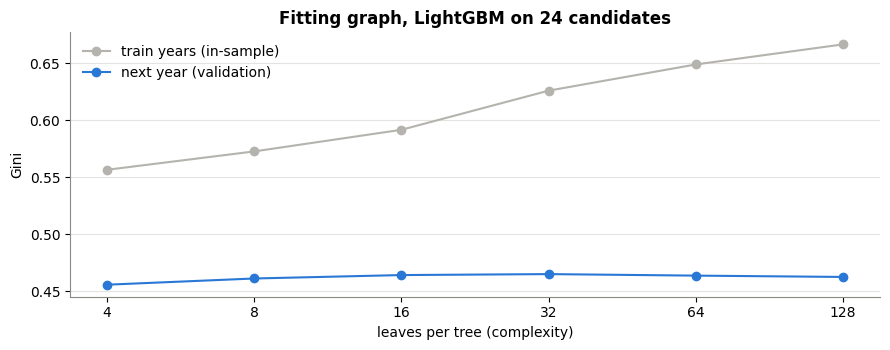

,leaves,train,validation,trees
0,4,0.5566,0.4559,366
1,8,0.5727,0.4614,181
2,16,0.5916,0.4644,122
3,32,0.6259,0.4652,124
4,64,0.6488,0.4639,96
5,128,0.6664,0.4627,90


In [4]:
# Fitting graph: vary tree size around the best 24-feature setting.
base = dict(TUNED["24 candidates"]["params"])
graph = []
for nl in [4, 8, 16, 32, 64, 128]:
    va, it, tr_ = lgbm_cv(ALL, {**base, "num_leaves": nl}, train_gini=True)
    graph.append({"leaves": nl, "train": tr_, "validation": va, "trees": it})
graph = pd.DataFrame(graph)
fig, ax = plt.subplots()
ax.plot(graph["leaves"], graph["train"], color=GREY, marker="o", label="train years (in-sample)")
ax.plot(graph["leaves"], graph["validation"], color=BLUE, marker="o", label="next year (validation)")
ax.set_xscale("log", base=2); ax.set_xticks(graph["leaves"], graph["leaves"].astype(str))
ax.set_xlabel("leaves per tree (complexity)"); ax.set_ylabel("Gini"); ax.legend(frameon=False)
ax.set_title("Fitting graph, LightGBM on 24 candidates")
plt.tight_layout(); plt.show()
graph.round(4)

### What the result shows
* **Tuned LightGBM, year-ahead validation:** 0.456 with the six v1 features, **0.465** with all 24 candidates. The two searches settle on similar trees (about 27 leaves, learning rate about 0.04, 80 to 100 trees).
* **Fitting graph:** the train Gini keeps climbing as trees grow (0.557 at 4 leaves, 0.666 at 128), while the next-year Gini peaks around 16 to 32 leaves (0.465) and then falls slightly. The widening gap is what the model memorises from the training years that does not carry to the next year. Early stopping and the moderate tree size keep that in check.

### Recommended action
Use the tuned settings for the final LightGBM challengers.

## Step 3. CatBoost

### Why this step
CatBoost handles categories with *ordered target statistics* (it encodes each category by the default rate of earlier loans only, which limits overfitting) and builds symmetric trees. Several published credit benchmarks find it the strongest boosting library on tabular data. Depth is chosen by the same forward-chaining validation, the tree count by early stopping.

In [5]:
CATS = [c for c in ALL if XS[c].dtype == object]


def catboost(cols, depth, iterations, **extra):
    return CatBoostClassifier(iterations=iterations, learning_rate=0.05, depth=depth, random_seed=SEED,
                              cat_features=[c for c in CATS if c in cols], verbose=0, thread_count=-1,
                              monotone_constraints={c: MONOTONE[c] for c in cols if c in MONOTONE},
                              allow_writing_files=False, **extra)


cat_cv = []
for depth in [4, 6]:
    v, its = [], []
    for fit_on, check_on in FOLDS:
        m = catboost(ALL, depth, 3000, eval_metric="AUC", od_type="Iter", od_wait=100).fit(
            XS.loc[fit_on, ALL], y[fit_on], eval_set=(XS.loc[check_on, ALL], y[check_on]))
        v.append(gini(y[check_on], m.predict_proba(XS.loc[check_on, ALL])[:, 1])); its.append(m.get_best_iteration())
    cat_cv.append({"depth": depth, "validation Gini": np.mean(v), "trees": int(np.mean(its)) + 1})
cat_cv = pd.DataFrame(cat_cv)
CAT_BEST = cat_cv.loc[cat_cv["validation Gini"].idxmax()]
cat_cv.round(4)

,depth,validation Gini,trees
0,4,0.4595,218
1,6,0.4616,224


### What the result shows
Depth 6 validates slightly better than depth 4 (0.462 vs 0.460), with about 220 trees. CatBoost's validation is level with the tuned LightGBM (0.465), without a settings search.

### Recommended action
Use the chosen depth and tree count for the final CatBoost challenger.

## Step 4. The Explainable Boosting Machine (glass box)

### Why this step
An EBM learns one curve per feature by boosting on one feature at a time, many rounds, in rotation; then it adds a small number of two-way tables for the most useful pairs of features. The result can be read like a scorecard: look up each feature's value on its curve, add the scores, convert to a PD.

For a model meant to be read, the inputs should not repeat each other. The EBM therefore uses the features that pass the v2 stability and logic screens (D-028): no raw inputs of derived features (country, the raw bureau scores, raw income), and no feature that fails the population-stability check. Two versions: **additive** (no pairs) and **10 interactions**.

In [6]:
bins_v2 = fit_bins(data.X[is_train], y[is_train], S.V2_MIN_BIN_SIZE, S.V2_MIN_PREBIN_SIZE, S.V2_MAX_N_PREBINS)
screen = screen_features(bins_v2, data.X, y, sample, country, reg)
CLEAN = screen.shortlist
print(f"EBM inputs ({len(CLEAN)}):", CLEAN)
print("Screened out:", screen.table.loc[screen.table["reason"] != "kept", "reason"].to_dict())


def ebm(interactions, fit_on=is_train):
    return ExplainableBoostingClassifier(interactions=interactions, outer_bags=8, random_state=SEED,
                                         n_jobs=-1).fit(XS.loc[fit_on, CLEAN], y[fit_on])


ebm_cv = []
for inter in [0, 10]:
    v = [gini(y[c], ebm(inter, f).predict_proba(XS.loc[c, CLEAN])[:, 1]) for f, c in FOLDS]
    ebm_cv.append({"interactions": inter, "validation Gini": np.mean(v)})
pd.DataFrame(ebm_cv).round(4)

EBM inputs (16): ['country_bureau_grade', 'days_since_first_loan', 'NoOfPreviousLoansBeforeLoan', 'days_since_last_loan', 'AmountOfPreviousLoansBeforeLoan', 'NewCreditCustomer', 'HomeOwnershipType', 'ExistingLiabilities', 'AppliedAmount', 'Amount', 'LiabilitiesTotal', 'income_vs_country_median', 'Education', 'PreviousEarlyRepaymentsCountBeforeLoan', 'ApplicationSignedHour', 'ApplicationSignedWeekday']
Screened out: {'Country': 'input of country_bureau_grade', 'CreditScoreEeMini': 'input of country_bureau_grade', 'MonthlyPaymentDay': 'country effect (within-country correlation +0.11)', 'CreditScoreFiAsiakasTietoRiskGrade': 'input of country_bureau_grade', 'IncomeTotal': 'country effect (within-country correlation +0.77)', 'VerificationType': 'population shift, PSI 1.00', 'LoanDuration': 'population shift, PSI 0.28', 'EmploymentDurationCurrentEmployer': 'population shift, PSI 0.32'}


,interactions,validation Gini
0,0,0.4524
1,10,0.4562


### What the result shows
* The screens keep **16 features**. They drop `Country` and the two raw bureau scores (replaced by `country_bureau_grade`), raw income (replaced by `income_vs_country_median`) and `MonthlyPaymentDay` (a country effect). Three features fail the stability check: `VerificationType` (PSI 1.00), `EmploymentDurationCurrentEmployer` (0.32) and `LoanDuration` (0.28).
* **Validation:** additive EBM 0.452; with 10 interactions 0.456. The pairs add about 0.004.

### Recommended action
Fit both EBMs on the whole train sample for the comparison.

## Step 5. The final comparison: test and out-of-time

### Why this step
Each challenger is refitted on the whole train sample with its chosen settings and scored **once** on the test and out-of-time samples, next to the v1 champion and Bondora's PD. A paired bootstrap of the Gini difference (the same resampled loans scored by both models) shows whether a gap is larger than chance.

In [7]:
def fit_lgbm(cols, key, frame=None):
    frame = X if frame is None else frame
    t = TUNED[key]
    return lgbm(cols, n_estimators=t["trees"], **t["params"]).fit(frame.loc[is_train, cols], y[is_train])


lgbm6, lgbm24 = fit_lgbm(SIX, "6 v1 features"), fit_lgbm(ALL, "24 candidates")
cat24 = catboost(ALL, int(CAT_BEST["depth"]), int(CAT_BEST["trees"])).fit(XS.loc[is_train, ALL], y[is_train])
ebm0, ebm10 = ebm(0), ebm(10)
MODELS = {
    "v1 champion scorecard": pd_champion,
    "LightGBM, 6 features": pd.Series(lgbm6.predict_proba(X[SIX])[:, 1], index=X.index),
    "LightGBM, 24 features": pd.Series(lgbm24.predict_proba(X[ALL])[:, 1], index=X.index),
    "CatBoost, 24 features": pd.Series(cat24.predict_proba(XS[ALL])[:, 1], index=X.index),
    "EBM, additive": pd.Series(ebm0.predict_proba(XS[CLEAN])[:, 1], index=X.index),
    "EBM, 10 interactions": pd.Series(ebm10.predict_proba(XS[CLEAN])[:, 1], index=X.index),
    "Bondora PD": data.bondora_pd,
}


def paired_diff(mask, a, b, n_boot=300):
    """95% interval of Gini(a) - Gini(b) on the same resampled loans."""
    rng = np.random.default_rng(SEED)
    t, sa, sb = y[mask].to_numpy(), a[mask].to_numpy(), b[mask].to_numpy()
    d = [gini(t[i], sa[i]) - gini(t[i], sb[i]) for i in (rng.integers(0, len(t), len(t)) for _ in range(n_boot))]
    return np.percentile(d, [2.5, 97.5])


rows = []
for s_name, m in [("test", is_test), ("oot", is_oot)]:
    for name, p in MODELS.items():
        lo, hi = paired_diff(m, p, pd_champion) if name != "v1 champion scorecard" else (np.nan, np.nan)
        rows.append({"sample": s_name, "model": name, "gini": gini(y[m], p[m]), "ks": ks(y[m], p[m]),
                     "brier": brier(y[m], p[m]), "mean_pd": p[m].mean(),
                     "vs_champion_low": lo, "vs_champion_high": hi})
compare = pd.DataFrame(rows)
display(compare.pivot_table(index="model", columns="sample", values=["gini", "ks"], sort=False).round(3))
best = compare[(compare["sample"] == "test") & (compare["model"] != "Bondora PD")].set_index("model")["gini"].idxmax()
print("Best on test:", best)
for name in MODELS:
    if name not in (best, "Bondora PD"):
        lo, hi = paired_diff(is_test, MODELS[name], MODELS[best])
        print(f"  test Gini, {name} minus {best}: {lo:+.3f} to {hi:+.3f}")
for name in ["LightGBM, 24 features", "CatBoost, 24 features", "EBM, 10 interactions"]:
    lo, hi = paired_diff(is_oot, MODELS[name], data.bondora_pd)
    print(f"OOT Gini, {name} minus Bondora PD: {lo:+.3f} to {hi:+.3f}")

gini            ks       
sample                  test    oot   test    oot
model                                            
v1 champion scorecard  0.459  0.368  0.354  0.267
LightGBM, 6 features   0.498  0.416  0.379  0.296
LightGBM, 24 features  0.515  0.439  0.387  0.310
CatBoost, 24 features  0.516  0.449  0.385  0.320
EBM, additive          0.501  0.417  0.377  0.299
EBM, 10 interactions   0.513  0.426  0.384  0.303
Bondora PD             0.414  0.405  0.314  0.300

Best on test: CatBoost, 24 features


  test Gini, v1 champion scorecard minus CatBoost, 24 features: -0.062 to -0.053


  test Gini, LightGBM, 6 features minus CatBoost, 24 features: -0.022 to -0.015


  test Gini, LightGBM, 24 features minus CatBoost, 24 features: -0.003 to +0.001


  test Gini, EBM, additive minus CatBoost, 24 features: -0.020 to -0.011


  test Gini, EBM, 10 interactions minus CatBoost, 24 features: -0.008 to +0.000


OOT Gini, LightGBM, 24 features minus Bondora PD: +0.017 to +0.051


OOT Gini, CatBoost, 24 features minus Bondora PD: +0.028 to +0.060


OOT Gini, EBM, 10 interactions minus Bondora PD: +0.005 to +0.039


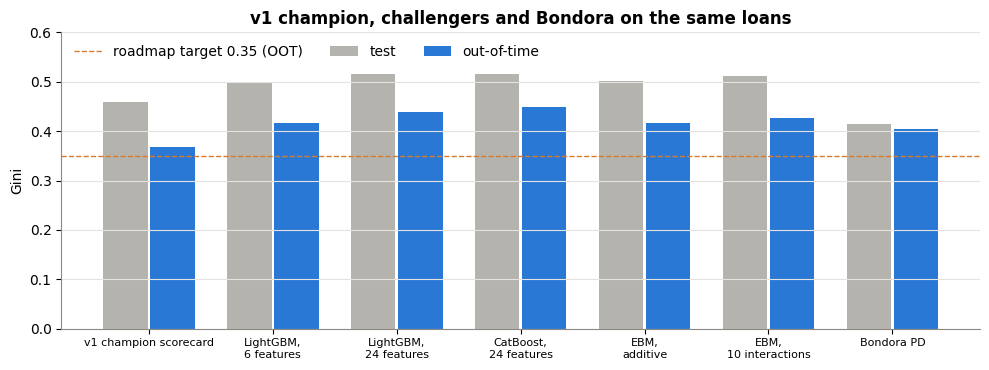

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
names = list(MODELS)
xs = np.arange(len(names))
for k, (s_name, colour) in enumerate([("test", GREY), ("oot", BLUE)]):
    g = compare[compare["sample"] == s_name].set_index("model").loc[names, "gini"]
    ax.bar(xs + (k - 0.5) * 0.38, g, width=0.36, color=colour, label={"test": "test", "oot": "out-of-time"}[s_name])
ax.axhline(0.35, color=ORANGE, linewidth=1, linestyle="--", label="roadmap target 0.35 (OOT)")
ax.set_xticks(xs, [n.replace(", ", ",\n") for n in names], fontsize=8); ax.set_ylabel("Gini"); ax.set_ylim(0, 0.6)
ax.set_title("v1 champion, challengers and Bondora on the same loans"); ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

### What the result shows
| | Test Gini | OOT Gini | OOT KS |
|---|---|---|---|
| v1 champion scorecard | 0.459 | 0.368 | 0.267 |
| LightGBM, 6 features | 0.498 | 0.416 | 0.296 |
| LightGBM, 24 features | 0.515 | 0.439 | 0.310 |
| **CatBoost, 24 features** | **0.516** | **0.449** | **0.320** |
| EBM, additive | 0.501 | 0.417 | 0.299 |
| **EBM, 10 interactions** | 0.513 | 0.426 | 0.303 |
| Bondora PD | 0.414 | 0.405 | 0.300 |

* **Every challenger beats the v1 champion by a wide margin**, on test and out of time (paired intervals far from zero).
* **CatBoost is best on test, but the top three are level.** The tuned LightGBM is within −0.003 to +0.001 of it and the 10-interaction EBM within −0.008 to 0.000.
* **The glass-box EBM ranks almost as well as the black boxes.** Its test Gini is 0.003 below CatBoost's, and every one of its effects can be read off a plot or a small table.
* **All three beat Bondora's own model out of time.** The 95% intervals: LightGBM +0.017 to +0.051, CatBoost +0.028 to +0.060, EBM +0.005 to +0.039. None of them uses Bondora's interest rate.

### Recommended action
The scorecard is leaving a lot on the table. Step 6 shows where; notebook 07 then puts it back inside a scorecard.

## Step 6. Where does the gain come from? (corrected)

### Why this step
A flexible model can beat a scorecard in three ways: **finer shapes** inside each feature, **interactions** between features, or **extra features**. The answer decides how the champion should be improved.

On the six v1 features we compare models that differ in one thing only. **Each one is tuned separately** (tree size by forward-chaining validation, tree count by early stopping): the first version of this step reused the free model's settings for the restricted ones, which under-trained them and gave the wrong answer.

* **LightGBM, additive:** no interactions allowed.
* **LightGBM, interactions with country only:** each feature may interact with `country_bureau_grade`.
* **LightGBM, free:** any interaction.
* **EBM, additive** and **EBM, 10 interactions**: the glass-box versions.

In [9]:
cb = SIX.index("country_bureau_grade")
RULES = {"additive": [[i] for i in range(len(SIX))],
         "country only": [[cb, i] for i in range(len(SIX)) if i != cb],
         "free": None}
X6 = XS[SIX]
decomp, pds = [], {}
for rule, inter in RULES.items():
    extra = {"interaction_constraints": inter} if inter else {}
    best_ = None
    for nl in [7, 15, 31, 63]:
        params = {"learning_rate": 0.05, "num_leaves": nl, "min_child_samples": 200, "subsample": 0.8,
                  "colsample_bytree": 0.8, **extra}
        va, it = lgbm_cv(SIX, params)
        if best_ is None or va > best_[0]:
            best_ = (va, it, params)
    m = lgbm(SIX, n_estimators=best_[1], **best_[2]).fit(X.loc[is_train, SIX], y[is_train])
    pds[f"LightGBM, {rule}"] = (pd.Series(m.predict_proba(X[SIX])[:, 1], index=X.index), best_[0])
for inter in [0, 10]:
    m = ExplainableBoostingClassifier(interactions=inter, outer_bags=8, random_state=SEED, n_jobs=-1)
    v = [gini(y[c], m.fit(X6[f], y[f]).predict_proba(X6[c])[:, 1]) for f, c in FOLDS]
    m.fit(X6[is_train], y[is_train])
    pds[f"EBM, {'additive' if inter == 0 else '10 interactions'}"] = (pd.Series(m.predict_proba(X6)[:, 1], index=X.index), np.mean(v))
pds = {"v1 champion scorecard": (pd_champion, np.nan), **pds}
for name, (p, va) in pds.items():
    r = {"model (6 v1 features)": name, "validation": va, "test": gini(y[is_test], p[is_test]),
         "oot": gini(y[is_oot], p[is_oot])}
    r.update({f"oot_{c}": gini(y[is_oot & country.eq(c)], p[is_oot & country.eq(c)]) for c in ["EE", "FI", "ES"]})
    decomp.append(r)
decomp = pd.DataFrame(decomp).set_index("model (6 v1 features)")
display(decomp.round(3))
X24 = MODELS["EBM, additive"]
print(f"Extra features (EBM additive on {len(CLEAN)} screened features vs on the 6): "
      f"test {gini(y[is_test], X24[is_test]) - decomp.loc['EBM, additive', 'test']:+.3f}, "
      f"oot {gini(y[is_oot], X24[is_oot]) - decomp.loc['EBM, additive', 'oot']:+.3f}")

,validation,test,oot,oot_EE,oot_FI,oot_ES
model (6 v1 features),,,,,,
v1 champion scorecard,NaN,0.459,0.368,0.323,0.154,0.117
"LightGBM, additive",0.445,0.481,0.398,0.342,0.170,0.106
"LightGBM, country only",0.448,0.489,0.400,0.343,0.205,0.149
"LightGBM, free",0.456,0.490,0.399,0.339,0.258,0.133
"EBM, additive",0.446,0.488,0.407,0.338,0.174,0.119
"EBM, 10 interactions",0.455,0.500,0.422,0.332,0.282,0.153


Extra features (EBM additive on 16 screened features vs on the 6): test +0.013, oot +0.010


### What the result shows
* **Finer shapes give most of the gain.** On the same six features, models with **no interactions at all** reach 0.481 (LightGBM) and 0.488 (EBM) on test, against the scorecard's 0.459. Out of time they reach 0.398 and 0.407, against 0.368. This reverses the first version of this notebook, whose additive model was under-trained.
* **Interactions add a smaller second step**: +0.009 (LightGBM) and +0.012 (EBM) on test. Out of time they help most in **Finland**: 0.170 → 0.258 for LightGBM and 0.174 → 0.282 for the EBM. Interactions with country alone recover about half of the LightGBM interaction gain on test.
* **Extra features add a third step**: the additive EBM on the 16 screened features beats the same EBM on the six v1 features by +0.013 test and +0.010 OOT.

In plain words, the v1 scorecard loses on three counts:
1. its shapes are too coarse and fixed one feature at a time;
2. one points table cannot let loan size and history differ by country;
3. its selection rules threw away features that still carry information.

### Recommended action
Fix all three inside the scorecard (notebook 07, D-028):
1. one coefficient per bin, with finer bins;
2. country-specific bins for loan size and the two history features;
3. the stability and logic screens instead of the IV, correlation and VIF rules.

## Step 7. Learning curve: would more data help?

### Why this step
If a model's test score is still rising when it uses all the training data, more data would help; if it has flattened, the limit is the information in the features (Provost and Fawcett, chapter 5). We refit the v1 champion (its coefficients, on its fixed bins) and the six-feature LightGBM on 10%, 25%, 50% and 100% of the train sample and score the test sample each time.

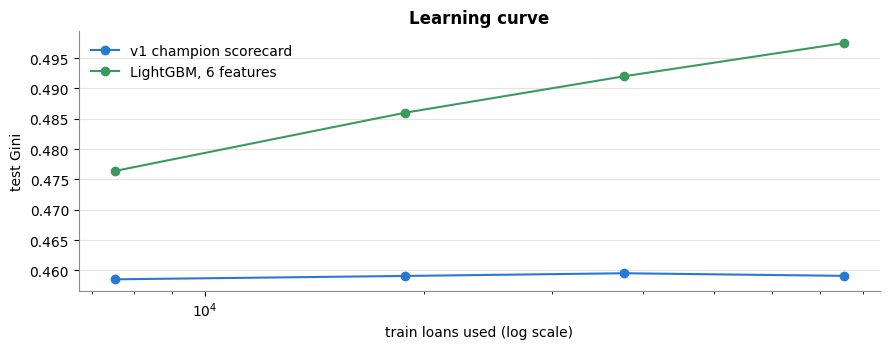

,train_share,train_loans,scorecard_test_gini,lightgbm6_test_gini
0,0.10,7530,0.4585,0.4764
1,0.25,18825,0.4591,0.4860
2,0.50,37651,0.4595,0.4920
3,1.00,75302,0.4591,0.4975


In [10]:
rng = np.random.default_rng(SEED)
train_idx = X.index[is_train].to_numpy()
order = rng.permutation(len(train_idx))
curve = []
t6 = TUNED["6 v1 features"]
for share in [0.10, 0.25, 0.50, 1.00]:
    part = pd.Index(train_idx[order[: int(share * len(train_idx))]])
    logit = sm.Logit(y[part], sm.add_constant(woe.loc[part, SIX])).fit(disp=0)
    p_sc = logit.predict(sm.add_constant(woe[SIX]))
    m = lgbm(SIX, n_estimators=t6["trees"], **t6["params"]).fit(X.loc[part, SIX], y[part])
    p_gb = pd.Series(m.predict_proba(X[SIX])[:, 1], index=X.index)
    curve.append({"train_share": share, "train_loans": len(part),
                  "scorecard_test_gini": gini(y[is_test], p_sc[is_test]),
                  "lightgbm6_test_gini": gini(y[is_test], p_gb[is_test])})
curve = pd.DataFrame(curve)
fig, ax = plt.subplots()
ax.plot(curve["train_loans"], curve["scorecard_test_gini"], color=BLUE, marker="o", label="v1 champion scorecard")
ax.plot(curve["train_loans"], curve["lightgbm6_test_gini"], color=GREEN, marker="o", label="LightGBM, 6 features")
ax.set_xscale("log"); ax.set_xlabel("train loans used (log scale)"); ax.set_ylabel("test Gini")
ax.set_title("Learning curve"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
curve.round(4)

### What the result shows
* **The scorecard is flat**: 0.459 with 10% of the train loans and 0.459 with 100%. Its coefficients are learned from 7,500 loans; more data cannot help a form this simple.
* **LightGBM keeps climbing** (0.476 → 0.498), more slowly at the end. Flexible shapes and interactions need many loans per segment.

### Recommended action
Improve the scorecard's form (notebook 07), not its sample. For the boosting models, refit as more loan years mature.

## Step 8. The D-012 sensitivity run: what is Bondora's price worth?

### Why this step
D-012 keeps `Interest` and `MonthlyPayment` out of every model: Bondora sets the rate from its own risk rating, so they carry Bondora's view of the borrower, and the project's purpose is an **independent** benchmark. The sensitivity run shows how much that view is worth, for the scorecard and for LightGBM.

These two columns are not allowed by the registry, so this step reads them separately and **never saves** a model that uses them. It is the one place the leakage guard is bypassed, on purpose and for analysis only.

In [11]:
con.register("sample_keys", samples[["loan_key"]])
price = (con.execute('SELECT loan_key, "Interest", "MonthlyPayment" FROM loans JOIN sample_keys USING (loan_key)')
            .df().set_index("loan_key").loc[X.index])
woe_alt = woe[SIX].copy()
for c in ["Interest", "MonthlyPayment"]:          # bins fitted on train only, as for every feature
    ob = OptimalBinning(c, dtype="numerical", min_bin_size=S.MIN_BIN_SIZE, monotonic_trend="auto_asc_desc")
    woe_alt[c] = ob.fit(price.loc[is_train, c].values, y[is_train].values).transform(price[c].values, metric="woe")


def scorecard_variant(cols):
    m = sm.Logit(y[is_train], sm.add_constant(woe_alt.loc[is_train, cols])).fit(disp=0)
    return m.predict(sm.add_constant(woe_alt[cols])), bool((m.params.drop("const") < 0).all())


variants = {"v1 champion (6 features)": scorecard_variant(SIX),
            "v1 champion + Interest": scorecard_variant(SIX + ["Interest"]),
            "v1 champion + Interest + MonthlyPayment": scorecard_variant(SIX + ["Interest", "MonthlyPayment"])}
X_price = X.join(price)
gb_price = fit_lgbm(ALL + ["Interest", "MonthlyPayment"], "24 candidates", frame=X_price)
variants["LightGBM 24 + price"] = (pd.Series(gb_price.predict_proba(X_price[ALL + ["Interest", "MonthlyPayment"]])[:, 1], index=X.index), None)
variants["Interest rate alone"] = (price["Interest"], None)
variants["Bondora PD"] = (data.bondora_pd, None)
pd.DataFrame({name: {"test": gini(y[is_test], p[is_test]), "oot": gini(y[is_oot], p[is_oot]), "all_signs_negative": s}
              for name, (p, s) in variants.items()}).T.round(3)

,test,oot,all_signs_negative
v1 champion (6 features),0.459092,0.368148,True
v1 champion + Interest,0.480833,0.476488,True
v1 champion + Interest + MonthlyPayment,0.480977,0.475094,False
LightGBM 24 + price,0.533554,0.511218,NaN
Interest rate alone,0.437364,0.39624,NaN
Bondora PD,0.414352,0.405088,NaN


### What the result shows
* **Bondora's interest rate alone (0.437 / 0.396) ranks almost as well as Bondora's own PD (0.414 / 0.405).** The rate *is* Bondora's risk view, priced.
* **Adding it to the v1 scorecard lifts OOT Gini by 0.11**, and LightGBM to 0.534 / 0.511. Our models and Bondora's know different things, so together they rank better than either.
* `MonthlyPayment` adds nothing once `Interest` is in, and it flips a sign.

### Recommended action
Keep D-012. A model that copies Bondora's price cannot benchmark Bondora. For interviews: *a lender's internal rating, when it has one, is the strongest single input to its application scorecard.* Nothing from this step is saved.

## Step 9. Calibration of the challengers

### Why this step
Every model here learned the default level of 2016 to 2019. Better ranking does not fix the level. We compare the mean predicted PD with the observed rate per sample, and per score decile out of time.

mean_pd         brier       
sample                   test    oot   test    oot
model                                             
v1 champion scorecard   0.315  0.269  0.185  0.137
LightGBM, 6 features    0.316  0.238  0.179  0.122
LightGBM, 24 features   0.315  0.237  0.177  0.121
CatBoost, 24 features   0.318  0.232  0.177  0.120
EBM, additive           0.315  0.231  0.179  0.124
EBM, 10 interactions    0.315  0.223  0.177  0.122
Bondora PD              0.264  0.174  0.193  0.116

Observed default rate: test 0.314  out-of-time 0.144


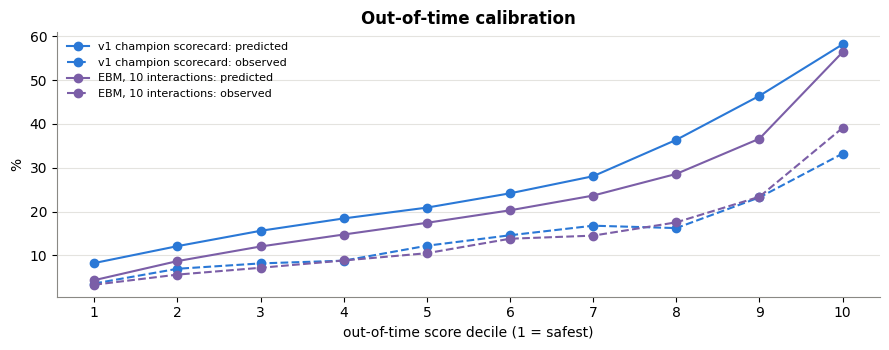

In [12]:
display(compare.pivot_table(index="model", columns="sample", values=["mean_pd", "brier"], sort=False).round(3))
print("Observed default rate: test", round(y[is_test].mean(), 3), " out-of-time", round(y[is_oot].mean(), 3))
fig, ax = plt.subplots()
for name, colour in [("v1 champion scorecard", BLUE), ("EBM, 10 interactions", PURPLE)]:
    d = pd.DataFrame({"pd": MODELS[name][is_oot], "y": y[is_oot]})
    d["decile"] = pd.qcut(d["pd"].rank(method="first"), 10, labels=False) + 1
    g = d.groupby("decile").agg(predicted=("pd", "mean"), observed=("y", "mean")) * 100
    ax.plot(g.index, g["predicted"], color=colour, marker="o", label=f"{name}: predicted")
    ax.plot(g.index, g["observed"], color=colour, marker="o", linestyle="--", label=f"{name}: observed")
ax.set_xlabel("out-of-time score decile (1 = safest)"); ax.set_ylabel("%"); ax.set_xticks(range(1, 11))
ax.set_title("Out-of-time calibration"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### What the result shows
* **Every model predicts 22% to 27% default out of time against an observed 14.4%.** They all learned the 2016 to 2019 level. The challengers are a little closer than the scorecard (they also rank the riskiest loans more sharply), but none is calibrated.
* Inside each decile the predicted line follows the observed line in shape. The gap is a level shift.

### Recommended action
Every model needs the Phase 4 recalibration before its PDs are used. Recalibration changes levels, not ranking, so it does not change the Gini comparison.

## Step 10. Save the challengers and their predictions

### Why this step
Notebook 07 compares the new champion with these challengers on the same loans, and Phase 4 explains them. LightGBM saves its trees as text; the EBM and CatBoost are saved with pickle and CatBoost's own format. The PDs of every model go into one file. The D-012 price model is not saved.

In [13]:
lgbm24.booster_.save_model(str(PROC / "challenger_lgbm.txt"))
cat24.save_model(str(PROC / "challenger_catboost.cbm"))
with open(PROC / "challenger_ebm.pkl", "wb") as fh:
    pickle.dump({"model": ebm10, "features": CLEAN}, fh)
preds = pd.DataFrame({k: v for k, v in MODELS.items()}).assign(sample=sample)
preds.to_parquet(PROC / "challenger_predictions.parquet")
(PROC / "challenger_metrics.json").write_text(json.dumps({
    "lightgbm": {"features": ALL, "monotone": {c: MONOTONE[c] for c in ALL if c in MONOTONE}, **TUNED["24 candidates"]},
    "catboost": {"depth": int(CAT_BEST["depth"]), "trees": int(CAT_BEST["trees"])},
    "ebm": {"features": CLEAN, "interactions": 10},
    "metrics": compare.round(4).to_dict(orient="records"),
}, indent=2, default=float), encoding="utf-8")
again = lgb.Booster(model_file=str(PROC / "challenger_lgbm.txt"))
assert np.allclose(again.predict(X[ALL]), MODELS["LightGBM, 24 features"].to_numpy())
print("Saved the three challengers and challenger_predictions.parquet; the reloaded LightGBM gives identical PDs")

Saved the three challengers and challenger_predictions.parquet; the reloaded LightGBM gives identical PDs


### What the result shows
The saved LightGBM reproduces its PDs exactly.

### Recommended action
None.

## Step 11. Summary of findings and recommended actions

| Question | Finding | Recommended action |
|---|---|---|
| Do flexible models rank better? | Yes: +0.04 to +0.06 test and +0.05 to +0.08 OOT Gini over the v1 scorecard | The v1 form leaves performance on the table |
| Which challenger is best? | CatBoost, LightGBM and the 10-interaction EBM are level on test (0.513 to 0.516); CatBoost leads out of time | Keep the EBM as the main challenger (glass box), the two boosting models as benchmarks |
| Do they beat Bondora? | Yes, all three, out of time, without Bondora's price | |
| Where does the gain come from? | Mostly finer, jointly fitted shapes; then interactions (mainly Finland); then extra features | Notebook 07: champion v2 |
| Monotone constraints | Loan size, last-loan gap and liabilities are not monotone in the data | Keep only the five data-checked constraints (D-029) |
| More data? | Scorecard flat from 10% of train; boosting still rising | Improve the scorecard's form |
| Bondora's price (D-012) | Interest alone ≈ Bondora PD; adding it gives +0.11 OOT | Keep D-012 |
| Calibration | Every model over-predicts OOT (22 to 27% vs 14%) | Phase 4 recalibration |

### What this means for the champion

The v1 scorecard should not stay champion as it is: the gap is too large and, by step 6, it is mostly a gap of **shapes and features**, which a scorecard can close. Notebook 07 builds champion v2, a logical dummy-coded scorecard with country-specific bins, and compares it with these challengers. A bank would not promote CatBoost or LightGBM to champion: they need a separate explanation layer and cannot guarantee logical points. The EBM is the challenger to watch: it is level with them and fully readable.

### The challengers in one paragraph (for my video)

"I challenged my scorecard with three models, all tuned only on earlier years and tested once: LightGBM, CatBoost and an Explainable Boosting Machine. All three beat the scorecard by about five Gini points, and all three beat Bondora's own model out of time without using its interest rate. The glass-box EBM was level with the black boxes. The most useful part was the *why*. When I stopped the trees from combining features, most of the advantage stayed, so the scorecard was mainly losing on feature shapes, not on complex interactions. That also told me how to fix it, which is the next notebook."


In [14]:
con.close()   # release the warehouse file